# EDA: Natural Language Processing with Disaster Tweets

Задача: бинарная классификация твитов — про реальную катастрофу (`target=1`) или нет (`target=0`). Метрика соревнования — F1.

In [1]:
import re
import html
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.max_colwidth", 200)

train = pd.read_csv("../../data/raw/train.csv")
test = pd.read_csv("../../data/raw/test.csv")
print(train.shape, test.shape)
train.head()

(7613, 5) (3263, 4)


,id,keyword,location,text,target
0,1,NaN,NaN,Our Deeds are the Reason of this #earthquake May ALLAH Forgive us all,1
1,4,NaN,NaN,Forest fire near La Ronge Sask. Canada,1
2,5,NaN,NaN,All residents asked to 'shelter in place' are being notified by officers. No other evacuation or shelter in place orders are expected,1
3,6,NaN,NaN,"13,000 people receive #wildfires evacuation orders in California",1
4,7,NaN,NaN,Just got sent this photo from Ruby #Alaska as smoke from #wildfires pours into a school,1


## Пропуски и типы

In [2]:
pd.DataFrame({
    "train_na": train.isna().mean().round(3),
    "test_na": test.isna().mean().round(3),
    "train_nunique": train.nunique(),
})

,train_na,test_na,train_nunique
id,0.000,0.000,7613
keyword,0.008,0.008,221
location,0.333,0.339,3341
target,0.000,NaN,2
text,0.000,0.000,7503


## Баланс классов

target
0    4342
1    3271
Name: count, dtype: int64
target
0    0.57
1    0.43
Name: count, dtype: float64


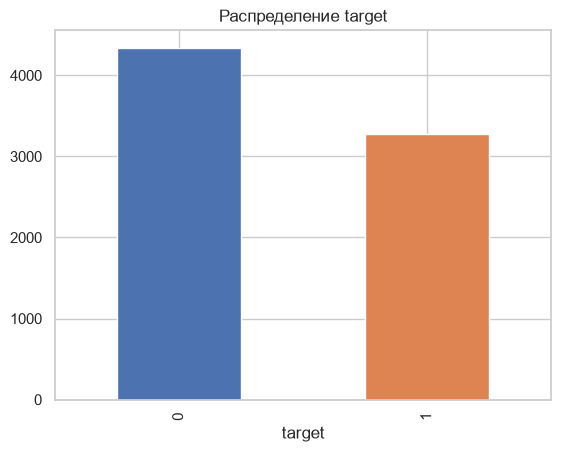

In [3]:
vc = train["target"].value_counts()
print(vc, (vc / len(train)).round(3), sep="\n")
ax = vc.plot.bar(color=["#4c72b0", "#dd8452"])
ax.set_title("Распределение target")
plt.show()

## Примеры

In [4]:
for t in (0, 1):
    print(f"--- target={t}")
    for s in train[train.target == t].sample(5, random_state=1).text:
        print("  ", s)

--- target=0
   Businesses are deluged with invoices. Make yours stand out with colo r or shape and it's lzkely to rise to the top of the pay' pile.
   http://t.co/Ns1AgGFNxz #shoes Asics GT-II Super Red 2.0 11 Ronnie Fieg Kith Red White 3M x gel grey volcano 2 http://t.co/oD250zshFy
   @thomasvissman22 @KeithyyL Keithyy gettin burned outta the blocks and on social media.... http://t.co/dlkuFtLQnF
   Kelby Tomlinson mild-mannered 2nd baseman for a great metropolitan team fights a never-ending battle for hits RBI and the #SFGiants way.
   Ignition Knock (Detonation) Sensor-Senso BECK/ARNLEY 158-1017 http://t.co/ryoByQJFCE http://t.co/LW9O2kDk18
--- target=1
   Bioterrorism public health superbug biolabs epidemics biosurveillance outbreaks | Homeland Security News Wire http://t.co/cvhYGwcBZv
   rgj: Truck trailer catches fire in Reno http://t.co/kAF3WdRmTn
   Good thing there was actually just a legit fire in the mall and nobody evacuated!!
   @Pam_Palmater i agree with @perrybellegarde 

## Длина текстов

target              0       1
n_chars count  4342.0  3271.0
        mean     95.7   108.1
        std      35.9    29.3
        min       7.0    14.0
        25%      68.0    88.0
        50%     101.0   115.0
        75%     130.0   136.0
        max     157.0   151.0
n_words count  4342.0  3271.0
        mean     14.7    15.2
        std       6.2     5.1
        min       1.0     2.0
        25%      10.0    11.0
        50%      15.0    15.0
        75%      19.0    19.0
        max      31.0    30.0

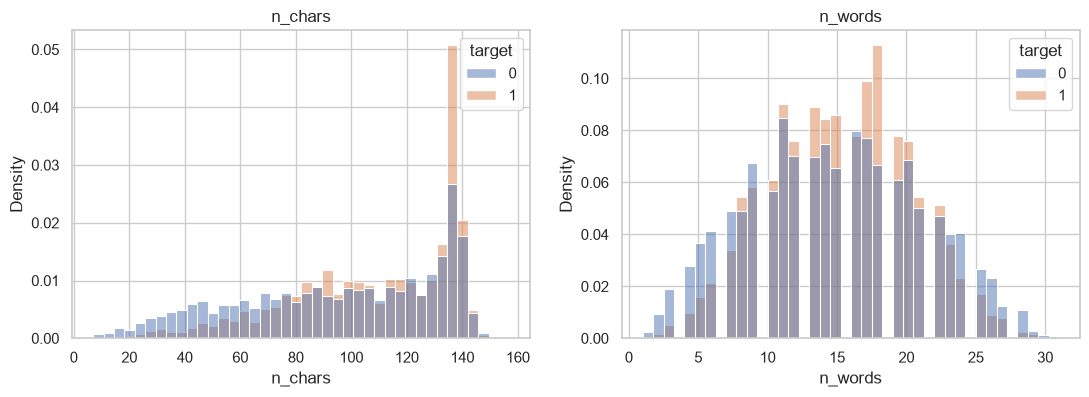

In [5]:
for df in (train, test):
    df["n_chars"] = df["text"].str.len()
    df["n_words"] = df["text"].str.split().str.len()

display(train.groupby("target")[["n_chars", "n_words"]].describe().T.round(1))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, col in zip(axes, ["n_chars", "n_words"]):
    sns.histplot(data=train, x=col, hue="target", bins=40, stat="density", common_norm=False, ax=ax)
    ax.set_title(col)
plt.show()

## keyword и location

уникальных keyword: 221 | test keyword не из train: 0

самые 'катастрофные' keyword:


,mean,size
keyword,,
derailment,1.000000,39
debris,1.000000,37
wreckage,1.000000,39
outbreak,0.975000,40
typhoon,0.973684,38
oil%20spill,0.973684,38
suicide%20bombing,0.969697,33
suicide%20bomber,0.967742,31
bombing,0.931034,29


самые 'мирные' keyword:


,mean,size
keyword,,
aftershock,0.000000,34
body%20bags,0.024390,41
ruin,0.027027,37
blazing,0.029412,34
body%20bag,0.030303,33
electrocute,0.031250,32
screaming,0.055556,36
traumatised,0.057143,35
panicking,0.060606,33


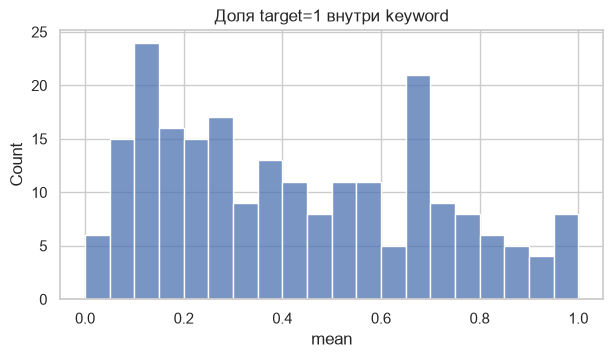

In [6]:
kw = train.assign(keyword=train.keyword.fillna("<NA>")).groupby("keyword")["target"].agg(["mean", "size"])
print("уникальных keyword:", train.keyword.nunique(), "| test keyword не из train:", len(set(test.keyword.dropna()) - set(train.keyword.dropna())))
print("\nсамые 'катастрофные' keyword:")
display(kw[kw["size"] >= 20].sort_values("mean", ascending=False).head(10))
print("самые 'мирные' keyword:")
display(kw[kw["size"] >= 20].sort_values("mean").head(10))

plt.figure(figsize=(7, 3.5))
sns.histplot(kw["mean"], bins=20)
plt.title("Доля target=1 внутри keyword")
plt.show()

In [7]:
from sklearn.metrics import f1_score
kw_rate = train.groupby(train.keyword.fillna("<NA>"))["target"].mean()
pred = (train.keyword.fillna("<NA>").map(kw_rate) > 0.5).astype(int)
print("F1 бейзлайна 'только keyword' (на train, оптимистично):", round(f1_score(train.target, pred), 4))

F1 бейзлайна 'только keyword' (на train, оптимистично): 0.6929


In [8]:
print("уникальных location:", train.location.nunique())
train.location.value_counts().head(15)

уникальных location: 3341


location
USA                104
New York            71
United States       50
London              45
Canada              29
Nigeria             28
UK                  27
Los Angeles, CA     26
India               24
Mumbai              22
Washington, DC      21
Kenya               20
Worldwide           19
Australia           18
Chicago, IL         18
Name: count, dtype: int64

## Дубликаты и конфликтующая разметка

In [9]:
dup = train[train.duplicated("text", keep=False)]
g = dup.groupby("text")["target"].agg(["nunique", "size", "mean"])
print("строк-дубликатов:", len(dup), "| уникальных дублирующихся текстов:", len(g))
print("текстов с конфликтующими метками:", (g["nunique"] > 1).sum(), "| строк:", g[g["nunique"] > 1]["size"].sum())
g[g["nunique"] > 1].sort_values("size", ascending=False).head(10)

строк-дубликатов: 179 | уникальных дублирующихся текстов: 69
текстов с конфликтующими метками: 18 | строк: 55


,nunique,size,mean
text,,,
The Prophet (peace be upon him) said 'Save yourself from Hellfire even if it is by giving half a date in charity.',2,6,0.333333
He came to a land which was engulfed in tribal war and turned it into a land of peace i.e. Madinah. #ProphetMuhammad #islam,2,6,0.333333
that horrible sinking feeling when youÛªve been at home on your phone for a while and you realise its been on 3G this whole time,2,4,0.500000
.POTUS #StrategicPatience is a strategy for #Genocide; refugees; IDP Internally displaced people; horror; etc. https://t.co/rqWuoy1fm4,2,4,0.750000
To fight bioterrorism sir.,2,4,0.500000
#Allah describes piling up #wealth thinking it would last #forever as the description of the people of #Hellfire in Surah Humaza. #Reflect,2,3,0.333333
#foodscare #offers2go #NestleIndia slips into loss after #Magginoodle #ban unsafe and hazardous for #humanconsumption,2,3,0.666667
Who is bringing the tornadoes and floods. Who is bringing the climate change. God is after America He is plaguing her\n \n#FARRAKHAN #QUOTE,2,3,0.333333
CLEARED:incident with injury:I-495 inner loop Exit 31 - MD 97/Georgia Ave Silver Spring,2,3,0.666667


In [10]:
print("пересечение текстов train/test:", len(set(train.text) & set(test.text)))

пересечение текстов train/test: 68


## Спецсимволы: URL, @, #, HTML-сущности, не-ASCII

In [11]:
feats = {
    "has_url": r"https?://\S+",
    "has_mention": r"@\w+",
    "has_hashtag": r"#\w+",
    "has_html_entity": r"&\w+;",
    "has_non_ascii": r"[^\x00-\x7f]",
    "has_number": r"\d",
}
for df in (train, test):
    for name, pat in feats.items():
        df[name] = df.text.str.contains(pat, regex=True)
    df["upper_ratio"] = df.text.apply(lambda s: sum(c.isupper() for c in s) / max(1, sum(c.isalpha() for c in s)))
    df["n_punct"] = df.text.str.count(r"[^\w\s]")

display(train.groupby("target")[list(feats) + ["upper_ratio", "n_punct"]].mean().T.round(3))
print("пример HTML-сущностей:", train.text.str.findall(r"&\w+;").explode().value_counts().head(5).to_dict())

target,0,1
has_url,0.414,0.664
has_mention,0.309,0.204
has_hashtag,0.204,0.262
has_html_entity,0.051,0.042
has_non_ascii,0.080,0.107
has_number,0.496,0.725
upper_ratio,0.128,0.134
n_punct,6.298,7.579


пример HTML-сущностей: {'&amp;': 342, '&gt;': 88, '&lt;': 27}


## Частотные слова и биграммы по классам

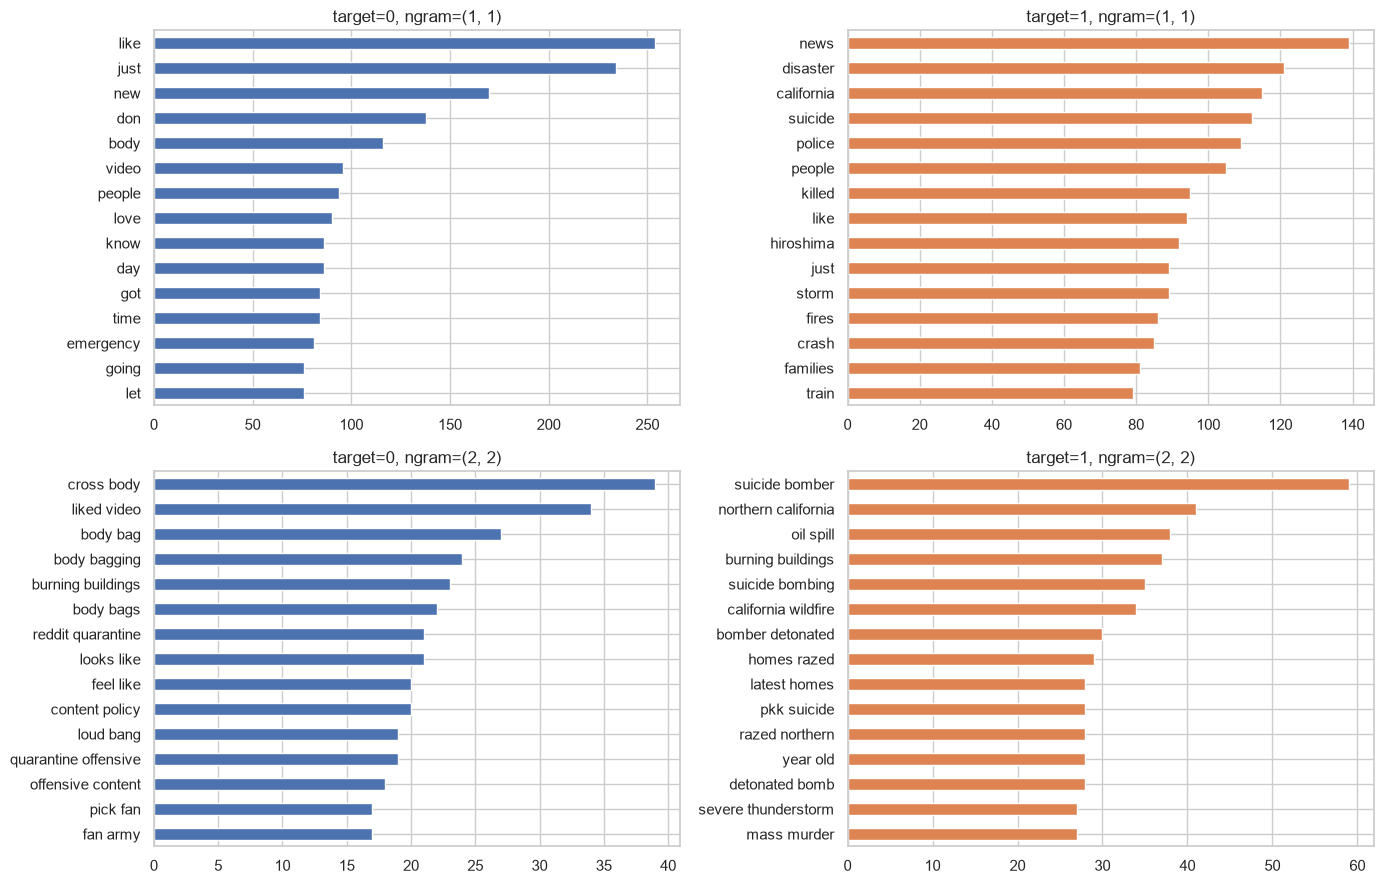

In [12]:
from sklearn.feature_extraction.text import CountVectorizer, ENGLISH_STOP_WORDS

def clean(s):
    s = html.unescape(s).lower()
    s = re.sub(r"https?://\S+", " ", s)
    s = re.sub(r"@\w+", " ", s)
    return s

def top_ngrams(texts, n=(1, 1), k=15):
    cv = CountVectorizer(ngram_range=n, stop_words=list(ENGLISH_STOP_WORDS), token_pattern=r"(?u)\b[a-z][a-z]+\b")
    X = cv.fit_transform(texts)
    s = np.asarray(X.sum(0)).ravel()
    idx = s.argsort()[::-1][:k]
    return pd.Series(s[idx], index=cv.get_feature_names_out()[idx])

fig, axes = plt.subplots(2, 2, figsize=(14, 9))
for j, t in enumerate((0, 1)):
    texts = train[train.target == t].text.map(clean)
    for i, n in enumerate([(1, 1), (2, 2)]):
        top_ngrams(texts, n).iloc[::-1].plot.barh(ax=axes[i, j], color="#4c72b0" if t == 0 else "#dd8452")
        axes[i, j].set_title(f"target={t}, ngram={n}")
plt.tight_layout()
plt.show()

## Сравнение train и test

In [13]:
cols = ["n_chars", "n_words", "has_url", "has_mention", "has_hashtag", "keyword"]
pd.DataFrame({
    "train": [train.n_chars.mean(), train.n_words.mean(), train.has_url.mean(), train.has_mention.mean(), train.has_hashtag.mean(), train.keyword.isna().mean()],
    "test": [test.n_chars.mean(), test.n_words.mean(), test.has_url.mean(), test.has_mention.mean(), test.has_hashtag.mean(), test.keyword.isna().mean()],
}, index=["mean_chars", "mean_words", "url_share", "mention_share", "hashtag_share", "keyword_na"]).round(3)

,train,test
mean_chars,101.037,102.108
mean_words,14.904,14.965
url_share,0.522,0.530
mention_share,0.264,0.281
hashtag_share,0.229,0.245
keyword_na,0.008,0.008


In [14]:
from transformers import AutoTokenizer
tok = AutoTokenizer.from_pretrained("cardiffnlp/twitter-roberta-base")
lens = train.text.map(lambda s: len(tok(s)["input_ids"]))
print(lens.describe(percentiles=[0.5, 0.9, 0.99]).round(1))

count    7613.0
mean       32.7
std        12.2
min         4.0
50%        33.0
90%        48.0
99%        63.0
max        85.0
Name: text, dtype: float64


## Выводы

1. **Объём**: train — 7613 твитов, test — 3263. Задача маленькая, поэтому классические модели обучаются за секунды, а fine-tune base-трансформера реален даже на CPU.
2. **Баланс**: 57% / 43% (0 / 1). Дисбаланс умеренный: стратифицированного сплита и метрики F1 достаточно, ресэмплинг не нужен (`class_weight=balanced` проверяем как эксперимент).
3. **Длина**: в среднем 101 символ / 15 слов, максимум 157 символов. Твиты-катастрофы немного длиннее (медиана 115 против 101 символа). В токенах RoBERTa максимум 85, 99-й перцентиль — 63, поэтому `max_length=96` покрывает всё без обрезки.
4. **keyword**: пропусков <1%, 221 значение, все keyword из test есть в train. Признак сильный (F1≈0.69 одним keyword): `derailment`, `debris`, `wreckage` — почти всегда 1, `aftershock`, `body bags`, `ruin` — почти всегда 0. Пробуем приклеивать keyword к тексту. В keyword есть `%20` вместо пробела — заменяем.
5. **location**: треть пропусков, 3341 уникальное значение, мусор вроде «Worldwide». Для модели не используем.
6. **Дубликаты**: 69 текстов повторяются (179 строк), у 18 текстов (55 строк) **конфликтующие метки** — это шум разметки. В сплите оставляем один экземпляр с меткой большинства, а тексты с ничьей выкидываем: так не будет утечки дубликатов между train и val и противоречивых примеров.
7. **Спецсимволы**: URL есть в 52% твитов (66% у класса 1 против 41% у класса 0; новости приходят со ссылкой), числа — 73% против 50%, упоминания @ чаще у класса 0 (бытовые разговоры). Сами URL (`t.co/...`) уникальны и бесполезны, но **факт** наличия ссылки или числа информативен, поэтому заменяем их на токены `URL` / `NUM` / `USER`, а не удаляем.
8. **Шум**: HTML-сущности (`&amp;` — 342 раза, `&gt;`, `&lt;`), битая кодировка (`Ûª`), хештеги (`#wildfires`), повторы символов. Нужны `html.unescape`, снятие `#` и схлопывание повторов.
9. **Частотные слова**: у класса 1 — `fire`, `news`, `disaster`, `california`, `police`, `killed`, `suicide bomber`, `northern california`; у класса 0 — `like`, `just`, `new`, `body bag`, `cross body`. Многие «катастрофные» слова встречаются в обоих классах в переносном смысле, поэтому контекст важен, и трансформеры здесь должны выигрывать.
10. **train и test** распределены одинаково (длины, доля URL, @, #), 68 текстов test дословно есть в train.

**Что это значит для предобработки:**
- *Классика*: lowercase, `html.unescape`, замена URL/@/чисел на токены, снятие `#`. Эксперименты: со стоп-словами и без, лемматизация / стемминг / ничего, с keyword и без.
- *Трансформеры*: тяжёлая предобработка не нужна и даже вредна (стоп-слова и пунктуация несут смысл для контекста). Делаем только `html.unescape` и нормализацию `@user` / `http`, как при предобучении twitter-roberta.
